# Lesson 5: why it's universal, and how it relates to circuits

We now have $J(\theta)$ for any $\theta$ (one wire step) and $CZ$ (one edge). That set is universal:
$H = J(0)$, $R_z(\phi) \propto J(0)J(-\phi)$, $R_x(\phi)\propto J(-\phi)J(0)$, $\mathrm{CNOT} = H_t\,CZ\,H_t$, and
$\{R_x, R_z, \mathrm{CNOT}\}$ is a universal gate set. So **every circuit translates to a measurement pattern**:

* each $J$ on logical qubit $q$ adds one new vertex to wire $q$ and one edge;
* each $CZ$ adds an edge between the current vertices of two wires.

That's the whole compiler: `compile_jcz` in `mbqc/patterns.py`, about 20 lines. Running a pattern means: make the graph state,
measure vertices in order with the Pauli frame, undo the frame on the outputs. (This translation is the
"measurement calculus" of [Danos, Kashefi & Panangaden, arXiv:0704.1263](https://arxiv.org/abs/0704.1263); when a pattern can
be run deterministically is answered by *flow*, [Danos & Kashefi, arXiv:quant-ph/0506062](https://arxiv.org/abs/quant-ph/0506062).)

Conversely, any pattern can be read as a circuit: the 1D cluster wire is a sequence of one-bit teleportations
([Gottesman & Chuang, arXiv:quant-ph/9908010](https://arxiv.org/abs/quant-ph/9908010) for the gate-teleportation idea;
[Nielsen, arXiv:quant-ph/0504097](https://arxiv.org/abs/quant-ph/0504097) for the cluster-state review).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mbqc import *

rng = np.random.default_rng(2026)

In [2]:
circuit = [("Rx", 0, 0.3), ("Rz", 1, 1.1), ("CNOT", 0, 1), ("Rx", 1, -0.4),
           ("H", 0), ("CNOT", 1, 0), ("Rz", 0, 2.0), ("Rx", 2, 0.8), ("CNOT", 1, 2)]
jcz = to_jcz(circuit)
pattern = compile_jcz(3, jcz)
print(f"{len(circuit)} gates -> {len(jcz)} J/CZ gates -> graph with {pattern.n_nodes} qubits, "
      f"{len(pattern.edges)} edges, {sum(c[0] == 'M' for c in pattern.commands)} measurements")
print("outputs live on vertices", pattern.outputs)

psi = random_state(3, rng)
for trial in range(3):
    out, outcomes = run_pattern(pattern, psi, rng=rng)
    print("random outcomes", "".join(map(str, outcomes.values())),
          "-> fidelity with the circuit:", round(fidelity(out, run_circuit(3, circuit, psi)), 12))

9 gates -> 20 J/CZ gates -> graph with 20 qubits, 20 edges, 17 measurements
outputs live on vertices [15, 10, 19]


random outcomes 11110101111011100 -> fidelity with the circuit: 1.0
random outcomes 01001010110110100 -> fidelity with the circuit: 1.0
random outcomes 01111001100111001 -> fidelity with the circuit: 1.0


## Draw the resource

The graph is a set of horizontal wires (one per logical qubit) joined by rungs where the circuit has CZs.

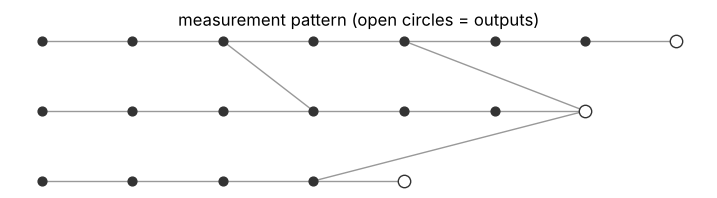

In [3]:
def draw(pattern, n_wires, ax):
    pos, wire_of = {}, {q: q for q in range(n_wires)}
    col = {q: 0 for q in range(n_wires)}
    for q in range(n_wires):
        pos[q] = (0, -q)
    for cmd in pattern.commands:
        if cmd[0] == "M":
            _, node, new, _ = cmd
            q = wire_of[node]
            col[q] += 1
            wire_of[new] = q
            pos[new] = (col[q], -q)
    for a, b in pattern.edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="0.6", lw=1, zorder=1)
    xs, ys = zip(*pos.values())
    ax.scatter(xs, ys, s=40, color="0.2", zorder=2)
    ax.scatter(*zip(*[pos[q] for q in pattern.outputs]), s=80, facecolor="white", edgecolor="0.2", zorder=3)
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(9, 2))
draw(pattern, 3, ax)
ax.set_title("measurement pattern (open circles = outputs)")
plt.show()

## The surprise: Clifford circuits take one round

Which measurements must wait for which outcomes? Run the Pauli frame *symbolically*: instead of bits, keep the set of
outcomes each byproduct depends on (XOR of sets = symmetric difference, the same `^` operator). A measurement at an angle
that isn't a multiple of $\pi/2$ must wait for the outcomes in its $X$ byproduct; Pauli measurements never wait.

Result: any Clifford circuit (H, S, CNOT), however deep, runs in **one round** of simultaneous measurements. Only non-Clifford
angles create a time order ([arXiv:quant-ph/0301052](https://arxiv.org/abs/quant-ph/0301052)). In circuit language this is
the Gottesman–Knill structure showing up as parallelism.

In [4]:
def random_circuit(n, depth, clifford):
    gates = []
    for _ in range(depth):
        for q in range(n):
            phi = rng.choice([np.pi / 2, np.pi, -np.pi / 2]) if clifford else rng.uniform(0, 2 * np.pi)
            gates.append(("Rz", q, phi))
            gates.append(("H", q))
        for q in range(0, n - 1, 2):
            gates.append(("CNOT", q, q + 1))
    return gates

print("depth   rounds(Clifford)   rounds(generic angles)")
for depth in (1, 2, 4, 8, 16):
    cl = measurement_depth(compile_jcz(4, to_jcz(random_circuit(4, depth, True))))
    gen = measurement_depth(compile_jcz(4, to_jcz(random_circuit(4, depth, False))))
    print(f"{depth:5d}   {cl:16d}   {gen:20d}")

depth   rounds(Clifford)   rounds(generic angles)
    1                  1                      1
    2                  1                      2
    4                  1                      4
    8                  1                      8
   16                  1                     16


## PennyLane's industrial version

PennyLane ships a transform, `pennylane.ftqc.convert_to_mbqc_formalism`, that does this compilation for real circuits (it follows
[arXiv:quant-ph/0301052](https://arxiv.org/abs/quant-ph/0301052) and reuses qubits so the register stays small). It needs a
sample-based output, so we compare measured frequencies with the exact probabilities. Each shot simulates the full
pattern, so we take only 300 shots.

In [5]:
import warnings

import pennylane as qml
from collections import Counter
from pennylane.ftqc import RotXZX, convert_to_mbqc_formalism, convert_to_mbqc_gateset, diagonalize_mcms

qml.decomposition.enable_graph()  # required by convert_to_mbqc_gateset
warnings.filterwarnings("ignore", message=".*GraphStatePrep")  # harmless: GraphStatePrep is kept as a native op
dev = qml.device("default.qubit")


def body():
    RotXZX(0.3, 0.5, 0.7, wires=0)
    qml.H(1)
    qml.CNOT([0, 1])
    qml.RZ(0.4, wires=1)


exact = qml.QNode(lambda: (body(), qml.probs(wires=[0, 1]))[1], dev)()


@diagonalize_mcms
@convert_to_mbqc_formalism
@convert_to_mbqc_gateset
@qml.set_shots(shots=300)
@qml.qnode(dev, mcm_method="one-shot")
def as_mbqc():
    body()
    return qml.sample(wires=[0, 1])


samples = np.asarray(as_mbqc())
freq = np.bincount(2 * samples[:, 0] + samples[:, 1], minlength=4) / len(samples)
print("exact probabilities  ", np.round(exact, 3))
print("MBQC frequencies     ", np.round(freq, 3))
tape = qml.workflow.construct_tape(as_mbqc)()
print("compiled circuit uses", len(tape.wires), "wires;", Counter(type(op).__name__ for op in tape.operations))

exact probabilities   [0.391 0.391 0.109 0.109]
MBQC frequencies      [0.413 0.417 0.093 0.077]
compiled circuit uses 15 wires; Counter({'Conditional': 26, 'MidMeasure': 25, 'Hadamard': 21, 'AdjointOperation': 10, 'CZ': 5, 'GraphStatePrep': 4})


**Takeaways**
* $\{J(\theta), CZ\}$ is universal, so circuits compile to patterns: one vertex per $J$, one edge per $CZ$.
* The resource (graph) depends only on the circuit's shape; the angles live in the measurements.
* Clifford parts run in a single round; only non-Clifford angles force waiting. That's why MBQC is attractive
  for hardware where measurement is fast but entangling gates are hard, like photons.